# Comparing the SVM and the random forest

Both models were tested on the same 12,077 test customers. This notebook checks 03 things

- **McNemar test** Are both models making different decisions or is the difference merely due to chance? (McNemar test)
- **Missing data check** How each model performs when a customer has many missing readings (Missing data check)
- **Error analysis** which customers both models get wrong and what they look like

It only reads the saved test predictions so it runs in about a minute

In [1]:
import os
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2, binomtest, spearmanr
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from pipeline import get_inputs_ready

DATA_DIR = '../data'
FIG_DIR = '../figures'
os.makedirs(FIG_DIR, exist_ok=True)

SVM_COLOUR = '#2b5c8f'
RF_COLOUR = '#d95f02'

plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

## 1. Load both prediction files

There is one row for each test customer in each file. We join them on `CONS_NO` and get the SVM answer and the forest answer for the same customer. We also incorporate some of the features from `features.csv` for the error analysis

In [2]:
# runs the model notebooks first if their files are missing
get_inputs_ready('comparison_tests.ipynb')

svm = pd.read_csv(os.path.join(DATA_DIR, 'svm_test_predictions.csv'))
rf = pd.read_csv(os.path.join(DATA_DIR, 'rf_test_predictions.csv'))
features = pd.read_csv(os.path.join(DATA_DIR, 'features.csv'))
with open(os.path.join(DATA_DIR, 'feature_info.json')) as f:
    feature_info = json.load(f)
with open(os.path.join(DATA_DIR, 'svm_info.json')) as f:
    svm_info = json.load(f)
with open(os.path.join(DATA_DIR, 'rf_info.json')) as f:
    rf_info = json.load(f)

# the forest cut has to come from training customers only
if 'cut' in rf_info:
    rf_cut = rf_info['cut']
else:
    rf_cut = rf_info['optimal_threshold']
    print('WARNING this rf_info.json is from the old forest notebook that picked its cut on the test set')
    print('rerun random_forest_model.ipynb after the fix before you use these numbers\n')

both = svm.merge(rf, on='CONS_NO', suffixes=('_svm', '_rf'))

# check both files have the same customers and the same labels
assert len(svm) == len(rf), 'the two files have a different number of customers'
assert len(both) == len(svm), 'the two files do not have the same customers'
assert (both['FLAG_svm'] == both['FLAG_rf']).all(), 'labels do not match'
both = both.rename(columns={'FLAG_svm': 'FLAG'})
both = both.drop(columns=['FLAG_rf'])

# features for the error analysis
# undo the log so the numbers are in normal units like kWh
look_at = ['mean_kwh', 'std_kwh', 'missing_share', 'longest_missing_run', 'zero_share', 'trend_slope', 'weekly_autocorr']
test_features = features[features['split'] == 'test'][['CONS_NO'] + look_at].copy()
for name in look_at:
    if name in feature_info['log_transformed']:
        values = test_features[name].to_numpy()
        test_features[name] = np.sign(values) * np.expm1(np.abs(values))
both = both.merge(test_features, on='CONS_NO')
assert len(both) == len(svm), 'some test customers are missing in features.csv'

y = both['FLAG'].to_numpy()
svm_pred = both['svm_pred'].to_numpy()
rf_pred = both['rf_pred'].to_numpy()
svm_score = both['svm_score'].to_numpy()
rf_score = both['rf_score'].to_numpy()

print(f"Test customers: {len(both):,} ({y.sum():,} thieves, {y.mean() * 100:.2f}%)")
print(f"SVM cut: {svm_info['cut']:.4f} on the SVM score")
print(f"Forest cut: {rf_cut:.4f} on the forest probability")

data/svm_test_predictions.csv is missing, so svm_model.ipynb has to run first.
All inputs for svm_model.ipynb are in place.
Running svm_model.ipynb (about 45 min)...


Finished svm_model.ipynb in 19.3 min.


All inputs for comparison_tests.ipynb are in place.


Test customers: 12,077 (1,074 thieves, 8.89%)
SVM cut: 0.5153 on the SVM score
Forest cut: 0.3935 on the forest probability


## 2. A quick comparison of the two models.

The same numbers as in the two model notebooks, solved again from the saved predictions to be sure that the files are correct. Accuracy must be read beside the baseline, since it is already 91% correct to say everyone is normal

In [3]:
models = [
    ('SVM', svm_pred, svm_score),
    ('Random forest', rf_pred, rf_score),
]

rows = []
for model_name, pred, score in models:
    rows.append({
        'model': model_name,
        'accuracy': (pred == y).mean(),
        'precision (theft)': precision_score(y, pred, zero_division=0),
        'recall (theft)': recall_score(y, pred),
        'F1 (theft)': f1_score(y, pred),
        'ROC-AUC': roc_auc_score(y, score),
        'PR-AUC': average_precision_score(y, score),
        'flagged': int(pred.sum()),
    })
quick_table = pd.DataFrame(rows).set_index('model')

print(f"Accuracy if every customer is called normal: {(y == 0).mean():.4f}\n")
quick_table.round(4)

Accuracy if every customer is called normal: 0.9111



,accuracy,precision (theft),recall (theft),F1 (theft),ROC-AUC,PR-AUC,flagged
model,,,,,,,
SVM,0.8664,0.3233,0.4590,0.3794,0.7857,0.3405,1525
Random forest,0.8873,0.3768,0.4088,0.3921,0.8015,0.3853,1165


In [4]:
# checks how the SVM and the forest think the same way about customers
rho = spearmanr(svm_score, rf_score)[0]
flagged_by_both = int(((svm_pred == 1) & (rf_pred == 1)).sum())
flagged_by_either = int(((svm_pred == 1) | (rf_pred == 1)).sum())

print(f"Spearman correlation between the SVM score and the forest score: {rho:.3f}")
print(f"Customers flagged by both models: {flagged_by_both:,} of {flagged_by_either:,} flagged by at least one")

Spearman correlation between the SVM score and the forest score: 0.805
Customers flagged by both models: 879 of 1,811 flagged by at least one


## 3. Which model gets each customer correct

For every test customer we check if each model was right. If both are correct or both are incorrect, the customer doesn't tell us which is better. Only the customers where they don't agree matter

- **b** = SVM right and forest wrong
- **c** = SVM wrong and forest right

In [5]:
svm_right = (svm_pred == y)
rf_right = (rf_pred == y)

both_right = int((svm_right & rf_right).sum())
b = int((svm_right & ~rf_right).sum())
c = int((~svm_right & rf_right).sum())
both_wrong = int((~svm_right & ~rf_right).sum())

agree_table = pd.DataFrame([[both_right, b], [c, both_wrong]],
                           index=['SVM right', 'SVM wrong'],
                           columns=['forest right', 'forest wrong'])

print(f"b (SVM right and forest wrong): {b:,}")
print(f"c (SVM wrong and forest right): {c:,}")
agree_table

b (SVM right and forest wrong): 340
c (SVM wrong and forest right): 592


,forest right,forest wrong
SVM right,10124,340
SVM wrong,592,1021


## 4. McNemar test

If both models were equally good then b and c would be about the same size. The test determines whether or not the difference between b and c is too large to be random

$$\chi^2 = \frac{(|b - c| - 1)^2}{b + c}$$

with 1 degree of freedom. The −1 is the usual continuity correction. If the p-value is under 0.05 the difference is real. If b + c is small (under 25) the exact binomial version is used instead

We run it three times

- **all test customers** this compares accuracy
- **thieves only** this compares the number of thieves caught (recall) by each model.
- **normal customers only** this compares false alarms

The split important because 91% of test customers are normal so the first test is mostly about normal customers

In [6]:
def mcnemar(svm_ok, rf_ok):
    # b indicates SVM right and forest wrong  
    # c indicates SVM wrong and forest right
    b = int((svm_ok & ~rf_ok).sum())
    c = int((~svm_ok & rf_ok).sum())
    if b + c == 0:
        return b, c, np.nan, 1.0, 'no disagreements'
    if b + c < 25:
        # too few disagreements. So use the exact test instead of chi square
        p = binomtest(b, b + c, 0.5).pvalue
        return b, c, np.nan, p, 'exact binomial'
    stat = (abs(b - c) - 1) ** 2 / (b + c)
    p = chi2.sf(stat, df=1)
    return b, c, stat, p, 'chi square with correction'


groups = [
    ('all test customers', np.ones(len(y), dtype=bool)),
    ('thieves only', y == 1),
    ('normal customers only', y == 0),
]

rows = []
for group_name, in_group in groups:
    b_g, c_g, stat, p, method = mcnemar(svm_right[in_group], rf_right[in_group])
    if p < 0.05:
        if b_g > c_g:
            result = 'SVM better, not luck'
        else:
            result = 'forest better, not luck'
    else:
        result = 'no real difference'
    rows.append({
        'group': group_name,
        'customers': int(in_group.sum()),
        'b (SVM right only)': b_g,
        'c (forest right only)': c_g,
        'chi2': stat,
        'p-value': p,
        'method': method,
        'result': result,
    })
mcnemar_table = pd.DataFrame(rows).set_index('group')
mcnemar_table.round(4)

,customers,b (SVM right only),c (forest right only),chi2,p-value,method,result
group,,,,,,,
all test customers,12077,340,592,67.5976,0.0000,chi square with correction,"forest better, not luck"
thieves only,1074,118,64,15.4341,0.0001,chi square with correction,"SVM better, not luck"
normal customers only,11003,222,528,124.0333,0.0000,chi square with correction,"forest better, not luck"


**How to read it** A small p-value indicates that the two models are indeed making different decisions with respect to these customers. Next, compare b and c to determine which is correct more frequently. If the big p-value, it might be due to chance, and we cannot conclude that one model is better at that cut.

Keep in mind. The test is regarding the yes or no decision at each model's cut. In section 2, ROC-AUC and PR-AUC compare the scores prior to any cut

## 5. Missing data check

The median missing share is much higher for thieves than for normal customers (20.8% compared to 8.3% for the training customers). Thus, a model could be capturing thieves primarily because their meter data has gaps. The test customers are divided into groups according to the amount of missing data, and each model is tested in each group

In [7]:
missing_groups = [
    ('under 10% missing', 0.0, 0.10),
    ('10% to 50% missing', 0.10, 0.50),
    ('over 50% missing', 0.50, 1.01),
]
missing = both['missing_share'].to_numpy()

rows = []
for group_name, low, high in missing_groups:
    in_group = (missing >= low) & (missing < high)
    y_g = y[in_group]
    for model_name, pred, score in models:
        pred_g = pred[in_group]
        score_g = score[in_group]
        # ROC-AUC needs both thieves and normal customers in the group
        if y_g.sum() > 0 and y_g.sum() < len(y_g):
            auc = roc_auc_score(y_g, score_g)
        else:
            auc = np.nan
        rows.append({
            'missing data': group_name,
            'model': model_name,
            'customers': int(in_group.sum()),
            'thieves': int(y_g.sum()),
            'theft share': y_g.mean(),
            'flagged': int(pred_g.sum()),
            'recall': recall_score(y_g, pred_g, zero_division=0),
            'precision': precision_score(y_g, pred_g, zero_division=0),
            'ROC-AUC': auc,
        })
missing_table = pd.DataFrame(rows).set_index(['missing data', 'model'])
missing_table.round(3)

customers  thieves  theft share  flagged  \
missing data       model                                                     
under 10% missing  SVM                 6160      410        0.067      516   
                   Random forest       6160      410        0.067      375   
10% to 50% missing SVM                 2870      306        0.107      459   
                   Random forest       2870      306        0.107      398   
over 50% missing   SVM                 3047      358        0.117      550   
                   Random forest       3047      358        0.117      392   

                                  recall  precision  ROC-AUC  
missing data       model                                      
under 10% missing  SVM             0.405      0.322    0.786  
                   Random forest   0.346      0.379    0.795  
10% to 50% missing SVM             0.533      0.355    0.815  
                   Random forest   0.526      0.405    0.829  
over 50% missing   SVM             0.458      0.298    0.721  
                   Random forest   0.380      0.347    0.755

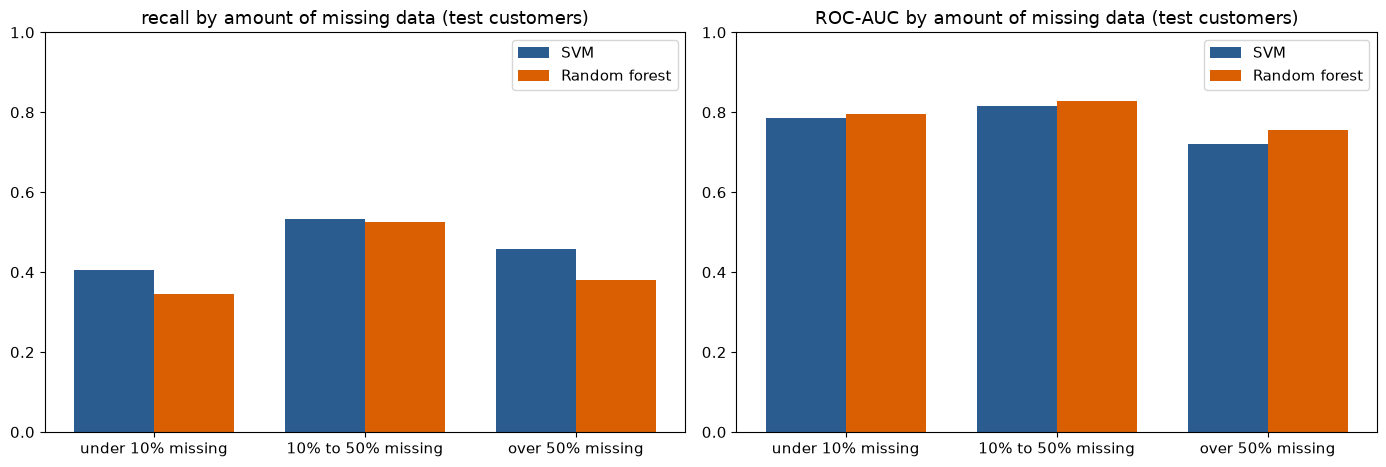

In [8]:
group_names = []
for group_name, low, high in missing_groups:
    group_names.append(group_name)
x = np.arange(len(group_names))
width = 0.38

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, measure in [(axes[0], 'recall'), (axes[1], 'ROC-AUC')]:
    svm_values = []
    rf_values = []
    for group_name in group_names:
        svm_values.append(missing_table.loc[(group_name, 'SVM'), measure])
        rf_values.append(missing_table.loc[(group_name, 'Random forest'), measure])
    ax.bar(x - width / 2, svm_values, width, color=SVM_COLOUR, label='SVM')
    ax.bar(x + width / 2, rf_values, width, color=RF_COLOUR, label='Random forest')
    ax.set_xticks(x)
    ax.set_xticklabels(group_names)
    ax.set_ylim(0, 1)
    ax.set_title(f'{measure} by amount of missing data (test customers)')
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step7_missing_data_check.png'), dpi=200, bbox_inches='tight')
plt.show()

**How to read it** If the recall rate is significantly higher in the "over 50% missing" group, then that model relies heavily on the fact that there is missing data in order to identify thieves. ROC-AUC within each group illustrates the performance of the model when missing data amount is similar. If it remains above 0.5 the model is also utilizing the other features, not just the gaps

## 6. Error analysis

Which thieves get missed and which normal customers get flagged by mistake. The median of some of the features is displayed for each group. The log is undone so the numbers are in normal units (kWh per day, share of days and so on)

In [9]:
svm_flag = (svm_pred == 1)
rf_flag = (rf_pred == 1)
thief = (y == 1)

error_groups = [
    ('thieves caught by both', thief & svm_flag & rf_flag),
    ('thieves caught by SVM only', thief & svm_flag & ~rf_flag),
    ('thieves caught by forest only', thief & ~svm_flag & rf_flag),
    ('thieves missed by both', thief & ~svm_flag & ~rf_flag),
    ('normal flagged by both', ~thief & svm_flag & rf_flag),
    ('normal flagged by one model', ~thief & (svm_flag != rf_flag)),
    ('normal flagged by neither', ~thief & ~svm_flag & ~rf_flag),
]

rows = []
for group_name, in_group in error_groups:
    row = {'group': group_name, 'customers': int(in_group.sum())}
    for name in look_at:
        if in_group.sum() > 0:
            row[name] = both.loc[in_group, name].median()
        else:
            row[name] = np.nan
    rows.append(row)
error_table = pd.DataFrame(rows).set_index('group')
error_table.round(3)

,customers,mean_kwh,std_kwh,missing_share,longest_missing_run,zero_share,trend_slope,weekly_autocorr
group,,,,,,,,
thieves caught by both,375,16.529,10.647,0.248,247.0,0.002,6.497,0.764
thieves caught by SVM only,118,7.291,6.089,0.168,161.5,0.045,1.993,0.643
thieves caught by forest only,64,12.460,8.779,0.195,160.0,0.032,2.621,0.729
thieves missed by both,517,6.304,3.436,0.172,157.0,0.003,0.091,0.536
normal flagged by both,504,11.123,8.492,0.314,252.0,0.006,4.821,0.727
normal flagged by one model,750,8.467,6.554,0.187,177.0,0.013,2.320,0.682
normal flagged by neither,9749,5.348,2.746,0.057,39.0,0.005,0.047,0.523


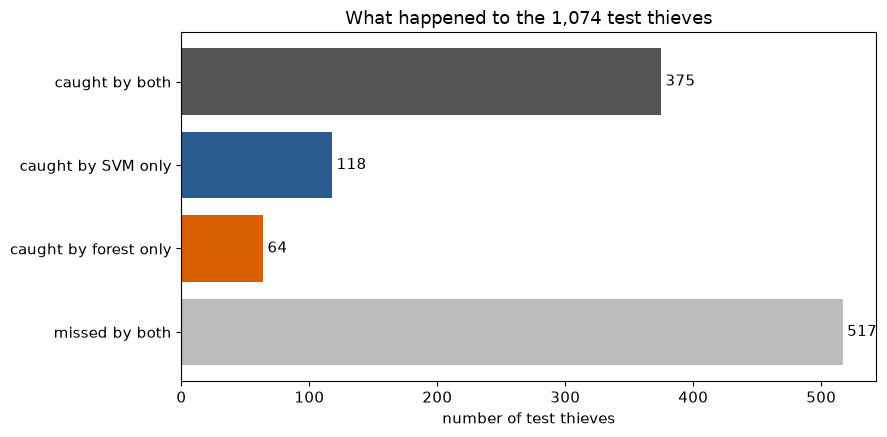

In [10]:
# take only the thief groups and count them for the bar chart
thief_groups = []
thief_counts = []
for group_name, in_group in error_groups:
    if group_name.startswith('thieves'):
        thief_groups.append(group_name.replace('thieves ', ''))
        thief_counts.append(int(in_group.sum()))

plt.figure(figsize=(9, 4.5))
bars = plt.barh(thief_groups, thief_counts, color=['#555555', SVM_COLOUR, RF_COLOUR, '#bbbbbb'])
plt.bar_label(bars, padding=3)
plt.gca().invert_yaxis()
plt.xlabel('number of test thieves')
plt.title(f'What happened to the {thief.sum():,} test thieves')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'step7_error_analysis_thieves.png'), dpi=200, bbox_inches='tight')
plt.show()

**How to read it** Compare "thieves missed by both" with "thieves caught by both". When the missed thieves use little electricity and have almost no missing data, they appear like normal customers in all the features we developed, so neither of the models can see them. That indicates what additional features or data would be required. The "normal" customers marked by both are the false alarms that an inspector would go to see for nothing

## 7. Save the results

Everything above goes into `data/comparison_info.json` for the report

In [11]:
def plain(value):
    # json can not save numpy numbers or nan
    # make numbers safe to save in json (normal float and no nan)
    if value is None:
        return None
    value = float(value)
    if np.isnan(value):
        return None
    return value


mcnemar_list = []
for group_name, row in mcnemar_table.iterrows():
    mcnemar_list.append({
        'group': group_name,
        'customers': int(row['customers']),
        'b_svm_right_only': int(row['b (SVM right only)']),
        'c_forest_right_only': int(row['c (forest right only)']),
        'chi2': plain(row['chi2']),
        'p_value': plain(row['p-value']),
        'method': row['method'],
        'result': row['result'],
    })

missing_list = []
for (group_name, model_name), row in missing_table.iterrows():
    missing_list.append({
        'group': group_name,
        'model': model_name,
        'customers': int(row['customers']),
        'thieves': int(row['thieves']),
        'recall': plain(row['recall']),
        'precision': plain(row['precision']),
        'roc_auc': plain(row['ROC-AUC']),
    })

error_list = []
for group_name, row in error_table.iterrows():
    item = {'group': group_name, 'customers': int(row['customers'])}
    for name in look_at:
        item['median_' + name] = plain(row[name])
    error_list.append(item)

comparison_info = {
    'test_customers': int(len(y)),
    'test_thieves': int(y.sum()),
    'svm_cut': plain(svm_info['cut']),
    'rf_cut': plain(rf_cut),
    'score_spearman': plain(rho),
    'flagged_by_both': flagged_by_both,
    'flagged_by_either': flagged_by_either,
    'agreement': {'both_right': both_right, 'b_svm_right_only': b, 'c_forest_right_only': c, 'both_wrong': both_wrong},
    'mcnemar': mcnemar_list,
    'missing_data_check': missing_list,
    'error_analysis': error_list,
}
with open(os.path.join(DATA_DIR, 'comparison_info.json'), 'w') as f:
    json.dump(comparison_info, f, indent=2)
print('Saved comparison_info.json')

Saved comparison_info.json
